# VoltRelay Energy — What is really driving failures, churn and margin?
**Gradient Learnings Data Analytics Hackathon · Nov 2026**

VoltRelay runs a battery-swapping network for EV two- and three-wheelers in six Indian cities. Between Jan 2024 and Jun 2025, swaps and revenue grew strongly, but service failures rose, new-rider retention fell and per-swap profitability eroded. This notebook investigates why.

**Contents**
0. Setup and data download
1. Data understanding
2. Data cleaning (every planted data-quality issue, found and handled)
3. Q1 · Network performance over time
4. Q2 & Q3 · Service failures, stations and geography
5. Q4 · Battery and equipment performance
6. Q5 · Pricing and partner economics
7. Q6 · Root cause of new-rider churn
8. Optional · Expansion waves and the budget decision
9. Key findings and recommendations

**Headline:** growth masked three independent problems:
1. **Heat-stressed Gen1 charging cabinets in hot cities run out of charged packs every summer.** This drives service failures, and the failures drive churn.
2. **A defective battery cohort from the new supplier (Kyron)** cut delivered range and erased the margin per swap.
3. **A re-negotiated contract with the largest fleet partner (ZipDrop)** turned it into the biggest loss-maker among 2W accounts.

> *AI disclosure: this analysis was produced with the assistance of Claude (Anthropic), used for code generation, analysis and drafting under the team's direction. All results are computed from the organizer's dataset in this notebook.*

## 0 · Setup and data download
The notebook downloads the eight CSVs from the organizer's shared Google Drive folder (about 840 MB). It runs top to bottom in Google Colab; use a standard runtime, since peak RAM is about 6 GB.

In [1]:
import sys, subprocess
from importlib.metadata import version, PackageNotFoundError
# Checked by metadata (not by importing), so an upgrade takes effect without restarting the runtime.
NEED = {"polars": "1.30", "gdown": "5.0", "pyarrow": "14.0", "scikit-learn": "1.3", "matplotlib": "3.7"}
def _v(s): return tuple(int(x) for x in s.split(".")[:2] if x.isdigit())
for pkg, minimum in NEED.items():
    try:
        ok = _v(version(pkg)) >= _v(minimum)
    except PackageNotFoundError:
        ok = False
    if not ok:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", f"{pkg}>={minimum}"], check=True)
print({pkg: version(pkg) for pkg in NEED})

{'polars': '1.36.1', 'gdown': '6.5.1', 'pyarrow': '23.0.1', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8'}


In [2]:
import os, gdown

DATA = "data/"
FOLDER_URL = "https://drive.google.com/drive/folders/1qsjGWrgmEvOaf2Is2fh7RgVEkKd1V3df"
FILES = ["swap_events.csv", "station_hourly_status.csv", "riders.csv", "batteries.csv",
         "support_tickets.csv", "stations.csv", "city_daily_context.csv", "fleet_partners.csv"]

def have_all():
    return all(os.path.exists(DATA + f) and os.path.getsize(DATA + f) > 0 for f in FILES)

attempt = 0
while not have_all() and attempt < 4:          # large files occasionally stop mid-way; gdown resumes them
    attempt += 1
    try:
        try:
            gdown.download_folder(FOLDER_URL, output=DATA, quiet=True, resume=True)
        except TypeError:                       # older gdown without resume=
            gdown.download_folder(FOLDER_URL, output=DATA, quiet=True)
    except Exception as e:
        print("download attempt", attempt, "failed:", e)
assert have_all(), "Data not complete: re-run this cell, or upload the 8 CSVs into a folder named data/"
for f in FILES:
    print(f"{f:28s} {os.path.getsize(DATA + f) / 1e6:8.1f} MB")

swap_events.csv                 728.7 MB
station_hourly_status.csv       108.4 MB
riders.csv                        2.1 MB
batteries.csv                     0.6 MB
support_tickets.csv               6.5 MB
stations.csv                      0.0 MB
city_daily_context.csv            0.2 MB
fleet_partners.csv                0.0 MB


In [3]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import date, timedelta
%matplotlib inline

pl.Config.set_tbl_rows(25); pl.Config.set_tbl_cols(20); pl.Config.set_fmt_str_lengths(40); pl.Config.set_tbl_width_chars(200)
BLUE, ORANGE, RED, GREEN, GREY, PURPLE = "#2563eb", "#ea580c", "#dc2626", "#16a34a", "#6b7280", "#7c3aed"
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "axes.titlesize": 11})
os.makedirs("figs", exist_ok=True)
EVENTS = {"2024-07-01": "Base price +₹5", "2024-08-01": "Wave 1", "2024-09-10": "Kyron 2W packs",
          "2024-11-01": "ZipDrop 12→28%", "2025-02-01": "Wave 2"}
def mark(ax):
    for d in EVENTS: ax.axvline(date.fromisoformat(d), color=GREY, lw=0.8, ls="--", alpha=0.6)

## 1 · Data understanding
Eight related tables. `swap_events` is the core fact table: one row per swap *attempt*, completed or not.

In [4]:
raw = pl.read_csv(DATA + "swap_events.csv", try_parse_dates=True, infer_schema_length=100_000)
stations_raw = pl.read_csv(DATA + "stations.csv", try_parse_dates=True)
riders_raw = pl.read_csv(DATA + "riders.csv", try_parse_dates=True)
batteries = pl.read_csv(DATA + "batteries.csv", try_parse_dates=True)
tickets_raw = pl.read_csv(DATA + "support_tickets.csv", try_parse_dates=True)
partners = pl.read_csv(DATA + "fleet_partners.csv", try_parse_dates=True)
city_daily = pl.read_csv(DATA + "city_daily_context.csv", try_parse_dates=True)
hourly_raw = pl.read_csv(DATA + "station_hourly_status.csv", try_parse_dates=True, infer_schema_length=100_000)

pl.DataFrame({"table": ["swap_events", "station_hourly_status", "riders", "batteries", "support_tickets", "stations", "city_daily_context", "fleet_partners"],
              "rows": [raw.height, hourly_raw.height, riders_raw.height, batteries.height, tickets_raw.height, stations_raw.height, city_daily.height, partners.height],
              "cols": [raw.width, hourly_raw.width, riders_raw.width, batteries.width, tickets_raw.width, stations_raw.width, city_daily.width, partners.width]})

table,rows,cols
str,i64,i64
"""swap_events""",3877013,22
"""station_hourly_status""",1487712,14
"""riders""",20000,12
"""batteries""",6500,13
"""support_tickets""",44000,12
"""stations""",152,22
"""city_daily_context""",3282,12
"""fleet_partners""",12,12


In [5]:
print("Date range:", raw["event_ts"].min(), "→", raw["event_ts"].max())
display(raw["event_type"].value_counts(sort=True).with_columns(share=pl.col("count") / pl.col("count").sum()))
display(raw["tariff_code"].value_counts(sort=True))
print("payment_mode values:", raw["payment_mode"].unique().to_list(), "→ uninformative (every row is partner_invoice); we use tariff_code / plan_type instead")

Date range: 2024-01-01 00:00:33 → 2025-06-30 23:59:23


event_type,count,share
str,u32,f64
"""swap_completed""",3645809,0.940365
"""failed_no_charged_battery""",134389,0.034663
"""abandoned_queue""",68533,0.017677
"""cancelled_by_rider""",16712,0.004311
"""failed_system_error""",11570,0.002984


tariff_code,count
str,u32
"""PARTNER""",2565478
"""STD""",1095936
"""PEAK""",177879
"""OFFPEAK""",37720


payment_mode values: ['partner_invoice'] → uninformative (every row is partner_invoice); we use tariff_code / plan_type instead


In [6]:
# Which fields are populated for which outcomes? Revenue fields are 0 for non-completed attempts.
raw.group_by("event_type").agg(
    pl.col("battery_in_id").null_count().alias("battery_in_null"), pl.col("battery_out_id").null_count().alias("battery_out_null"),
    pl.col("amount_charged_inr").mean().alias("avg_amount"), pl.col("queue_wait_sec").mean().alias("avg_queue_s"), pl.len().alias("n"))

event_type,battery_in_null,battery_out_null,avg_amount,avg_queue_s,n
str,u32,u32,f64,f64,u32
"""failed_no_charged_battery""",0,134389,0.0,29.498121,134389
"""failed_system_error""",11570,11570,0.0,44.417978,11570
"""cancelled_by_rider""",16712,16712,0.0,44.565701,16712
"""swap_completed""",0,0,63.943573,243.721747,3645809
"""abandoned_queue""",0,68533,0.0,702.557906,68533


In [7]:
display(raw.select(pl.col(["queue_wait_sec", "soc_in_pct", "soh_in_pct", "soc_out_pct", "soh_out_pct", "km_since_last_swap", "amount_charged_inr", "energy_to_recharge_kwh"])).describe())
display(stations_raw.group_by("city", "expansion_wave").len().pivot(on="expansion_wave", index="city", values="len"))
display(stations_raw["charger_generation"].value_counts(sort=True))

statistic,queue_wait_sec,soc_in_pct,soh_in_pct,soc_out_pct,soh_out_pct,km_since_last_swap,amount_charged_inr,energy_to_recharge_kwh
str,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",3.877013e6,3.848731e6,3.848731e6,3.645809e6,3.645809e6,3.848731e6,3.877013e6,3.645809e6
"""null_count""",0.0,28282.0,28282.0,231204.0,231204.0,28282.0,0.0,231204.0
"""mean""",242.953599,9.286564,88.169566,96.66453,88.409578,62.035149,60.130326,2.092923
"""std""",163.909468,4.445892,7.972944,3.372417,7.451896,20.441068,20.697864,0.812226
"""min""",0.0,1.0,55.2,80.0,54.7,-20.0,0.0,0.809
"""25%""",137.0,6.0,84.0,95.9,84.3,51.9,55.2,1.719
"""50%""",206.0,9.3,89.3,97.3,89.2,60.0,58.5,1.869
"""75%""",305.0,12.5,94.1,98.6,93.9,69.0,65.0,2.032
"""max""",2400.0,28.4,101.4,103.0,101.3,420.0,135.0,5.519


city,Wave1_2024H2,Wave2_2025H1,Launch
str,u32,u32,u32
"""Delhi NCR""",6,6,18
"""Bengaluru""",6,6,22
"""Mumbai""",4,5,13
"""Pune""",5,4,13
"""Jaipur""",4,4,10
"""Hyderabad""",5,5,16


charger_generation,count
str,u32
"""Gen2""",64
"""Gen1""",51
"""Gen3""",37


## 2 · Data cleaning
Each data-quality issue named in the brief is **tested against the data first** and then handled. Where the data does not match the brief's description, that is reported too.

### 2.1 Test stations

In [8]:
log = {}
is_test = pl.col("station_id").str.starts_with("STN-TST")
t = raw.filter(is_test)
print(f"Test-station events: {t.height:,}  (zero-value rows: {(t['amount_charged_inr'] == 0).sum():,}, all non-completed attempts)")
stations = stations_raw.filter(~is_test)
s = raw.filter(~is_test)
log["test_station_rows_removed"] = t.height

Test-station events: 62,031  (zero-value rows: 2,897, all non-completed attempts)


### 2.2 Firmware v3.2.0 timezone bug
The brief says v3.2.0 cabinets logged times 5h30m early between 10 Mar and 14 Apr 2025. We test this by comparing the mean hour of day by firmware inside and outside that window.

In [9]:
win = pl.col("event_ts").is_between(pl.datetime(2025, 3, 9, 18, 30), pl.datetime(2025, 4, 14, 18, 30))
before = s.with_columns(h=pl.col("event_ts").dt.hour()).group_by(win.alias("in_window"), "station_firmware").agg(mean_hour=pl.col("h").mean(), n=pl.len()).sort("in_window", "station_firmware")
display(before)

shift = pl.duration(hours=5, minutes=30)
bug = (pl.col("station_firmware") == "v3.2.0") & (pl.col("event_ts") + shift >= pl.datetime(2025, 3, 10)) & (pl.col("event_ts") + shift < pl.datetime(2025, 4, 15))
log["timestamps_shifted"] = s.filter(bug).height
s = s.with_columns(event_ts=pl.when(bug).then(pl.col("event_ts") + shift).otherwise(pl.col("event_ts")))
check = s.filter(pl.col("event_ts").is_between(pl.datetime(2025, 3, 10), pl.datetime(2025, 4, 15))).group_by("station_firmware").agg(mean_hour_after_fix=pl.col("event_ts").dt.hour().mean())
print(f"Shifted {log['timestamps_shifted']:,} events by +5h30m"); display(check)

in_window,station_firmware,mean_hour,n
bool,str,f64,u32
false,"""v3.2.0""",15.122628,1419894
false,"""v3.2.1""",15.133712,2037961
true,"""v3.2.0""",10.526387,141280
true,"""v3.2.1""",15.178191,215847


Shifted 141,280 events by +5h30m


station_firmware,mean_hour_after_fix
str,f64
"""v3.2.1""",15.177352
"""v3.2.0""",14.964022


### 2.3 Near-duplicate records
The brief describes duplicates as the same rider, station and batteries, seconds to minutes apart, linked to `offline_batch` sync. We test that definition first, then a looser one.

In [10]:
k = ["rider_id", "station_id", "battery_in_id"]
strict = s.filter(pl.col("battery_in_id").is_not_null()).sort(k + ["event_ts"]).with_columns(gap=pl.col("event_ts").diff().dt.total_seconds().over(k))
print("Same rider + station + battery within 10 min:", strict.filter(pl.col("gap") <= 600).height, "pairs  → the described pattern is essentially absent")

k = ["rider_id", "station_id"]
s = s.sort(k + ["event_ts"]).with_columns(_gap=pl.col("event_ts").diff().dt.total_seconds().over(k), _prev=pl.col("event_type").shift(1).over(k))
dup = ((pl.col("_gap") <= 180) & (pl.col("event_type") == "swap_completed") & (pl.col("_prev") == "swap_completed")).fill_null(False)
d = s.filter(dup)
print(f"Back-to-back completed swaps by same rider at same station within 180 s: {d.height:,}")
print(f"  share offline_batch among them: {(d['sync_mode'] == 'offline_batch').mean():.1%}  vs base rate {(s['sync_mode'] == 'offline_batch').mean():.1%}")
log["near_duplicates_removed"] = d.height
s = s.filter(~dup).drop("_gap", "_prev")

Same rider + station + battery within 10 min: 4 pairs  → the described pattern is essentially absent


Back-to-back completed swaps by same rider at same station within 180 s: 5,614
  share offline_batch among them: 15.6%  vs base rate 15.5%


A rider who has just received a charged pack cannot plausibly need a second swap within 3 minutes. We remove these 0.15% of rows, and note that they are **not** concentrated in offline sync, unlike the brief's description.

### 2.4 Outliers: odometer resets and sensor drift

In [11]:
log["km_negative"] = s.filter(pl.col("km_since_last_swap") < 0).height
log["km_over_200"] = s.filter(pl.col("km_since_last_swap") > 200).height
pct = ["soc_in_pct", "soh_in_pct", "soc_out_pct", "soh_out_pct"]
log["pct_over_100"] = {c: s.filter(pl.col(c) > 100).height for c in pct}
s = s.with_columns(km_valid=pl.col("km_since_last_swap").is_between(0, 200),
                   km_since_last_swap=pl.when(pl.col("km_since_last_swap").is_between(0, 200)).then(pl.col("km_since_last_swap")),
                   *[pl.col(c).clip(upper_bound=100.0) for c in pct])
print({k_: log[k_] for k_ in ["km_negative", "km_over_200", "pct_over_100"]})

{'km_negative': 7681, 'km_over_200': 7589, 'pct_over_100': {'soc_in_pct': 0, 'soh_in_pct': 3296, 'soc_out_pct': 3628, 'soh_out_pct': 2749}}


### 2.5 Rider city spellings

In [12]:
print(sorted(riders_raw["home_city"].unique().to_list()))
CITY = {"bengaluru": "Bengaluru", "bangalore": "Bengaluru", "blr": "Bengaluru", "delhi ncr": "Delhi NCR", "new delhi": "Delhi NCR",
        "delhi": "Delhi NCR", "gurgaon": "Delhi NCR", "gurugram": "Delhi NCR", "noida": "Delhi NCR", "del": "Delhi NCR",
        "mumbai": "Mumbai", "bombay": "Mumbai", "mum": "Mumbai", "hyderabad": "Hyderabad", "hyd": "Hyderabad",
        "pune": "Pune", "pun": "Pune", "jaipur": "Jaipur", "jai": "Jaipur"}
riders = riders_raw.with_columns(home_city=pl.col("home_city").str.strip_chars().str.to_lowercase().replace_strict(CITY, default=None),
                                 segment=pl.when(pl.col("partner_id").is_null()).then(pl.lit("independent")).otherwise(pl.lit("fleet")))
riders = riders.join(partners.select("partner_id", "partner_name"), on="partner_id", how="left")
assert riders["home_city"].null_count() == 0
riders["home_city"].value_counts(sort=True)

['BLR', 'Bangalore', 'Bengaluru', 'Bombay', 'Delhi', 'Delhi NCR', 'Gurgaon', 'HYD', 'Hyd', 'Hyderabad', 'JAI', 'Jaipur', 'MUM', 'Mumbai', 'New Delhi', 'PUN', 'Pune', 'bengaluru ', 'hyderabad', 'jaipur', 'pune']


home_city,count
str,u32
"""Bengaluru""",4310
"""Delhi NCR""",3886
"""Hyderabad""",3485
"""Pune""",2929
"""Mumbai""",2874
"""Jaipur""",2516


### 2.6 Support tickets: mislabelled categories and biased CSAT
Agent-assigned categories hide battery problems: riders blame "the bike" or "the scooter". We re-label using the comment text, which is in English and Hinglish.

In [13]:
tickets = tickets_raw.filter(~pl.col("station_id").fill_null("").str.starts_with("STN-TST"))
c = pl.col("rider_comment").str.to_lowercase()
tickets = tickets.with_columns(category_fixed=
    pl.when(c.str.contains("sab batteries discharge")).then(pl.lit("no_battery_available"))
    .when(c.str.contains("range|rnage|discharge|dying at|scooter weak|bike problem|vehicle|battery ka|battry ka")).then(pl.lit("battery_range"))
    .when(c.str.contains("no batt|charged batt|empty sta|nahi mila")).then(pl.lit("no_battery_available"))
    .when(c.str.contains("queue|line thi|waited")).then(pl.lit("long_queue"))
    .when(c.str.contains("amount|surcharge|charged extra")).then(pl.lit("billing_dispute"))
    .when(c.str.contains("app |app crash|qr|nearby")).then(pl.lit("app_issue"))
    .otherwise(pl.col("category")))
display(tickets.group_by("category", "category_fixed").len().sort("len", descending=True))
display(tickets.filter(pl.col("category") == "other")["rider_comment"].value_counts(sort=True).head(6))

category,category_fixed,len
str,str,u32
"""no_battery_available""","""no_battery_available""",11510
"""other""","""battery_range""",9385
"""low_range""","""battery_range""",6562
"""app_issue""","""app_issue""",5726
"""long_queue""","""long_queue""",5660
"""billing_dispute""","""billing_dispute""",4622


rider_comment,count
str,u32
"""general issue with the vehicle performan…",3241
"""bike problem lag raha hai overall""",3124
"""scooter weak lag raha hai aajkal""",3020


In [14]:
# CSAT is missing far more often for slow resolutions. Does that bias the average?
r_ = tickets.filter(pl.col("resolution_status") == "resolved").with_columns(speed=pl.col("resolution_hours").cut([4, 12, 24, 48]))
by = r_.group_by("speed").agg(n=pl.len(), scored_pct=pl.col("csat_score").is_not_null().mean() * 100, csat=pl.col("csat_score").mean()).sort("speed")
display(by)
print("Naive CSAT:", round(r_["csat_score"].mean(), 2), "| re-weighted to all resolved tickets:", round((by["n"] * by["csat"]).sum() / by["n"].sum(), 2))

speed,n,scored_pct,csat
cat,u32,f64,f64
"""(-inf, 4]""",1322,42.813918,3.606007
"""(12, 24]""",14488,43.387631,3.56952
"""(24, 48]""",5660,21.519435,3.596059
"""(4, 12]""",15261,44.092786,3.531431
"""(48, inf]""",693,22.077922,3.640523


Naive CSAT: 3.56 | re-weighted to all resolved tickets: 3.56


The response rate halves for slow tickets, but scores barely differ by speed, so the bias is small here. CSAT is too flat to explain behaviour and is not used as a driver.

### 2.7 Telemetry gaps
Blank telemetry is **not zero**. We keep blanks as null and use only `telemetry_status == 'ok'` hours for the heat analysis.

In [15]:
hourly = hourly_raw.filter(~pl.col("station_id").str.starts_with("STN-TST")).join(
    stations.select("station_id", "city", "charger_generation", "connectivity_tier"), on="station_id", how="left")
hourly.group_by("connectivity_tier", "telemetry_status").len().pivot(on="telemetry_status", index="connectivity_tier", values="len")

connectivity_tier,ok,partial,missing
str,u32,u32,u32
"""fair""",267660,11004,null
"""good""",938666,9550,null
"""poor""",208999,16193,9384


### 2.8 Enrichment and unit economics
We define per completed swap:
- **Revenue** = `amount_charged_inr`
- **Energy cost** = `energy_to_recharge_kwh` × the station's grid tariff
- **Battery wear** = pack purchase cost × (health points lost ÷ 30 points of usable life) ÷ the number of times that pack was issued. This charges each swap its share of the pack's degradation.
- **Contribution** = revenue − energy − wear. Site rent and maintenance are shown separately.

In [16]:
s = s.with_columns(
    completed=pl.col("event_type") == "swap_completed",
    failed=pl.col("event_type").is_in(["failed_no_charged_battery", "failed_system_error"]),
    stockout=pl.col("event_type") == "failed_no_charged_battery",
    abandoned=pl.col("event_type").is_in(["abandoned_queue", "cancelled_by_rider"]),
    date=pl.col("event_ts").dt.date(), month=pl.col("event_ts").dt.truncate("1mo").dt.date(), hour=pl.col("event_ts").dt.hour(),
    vclass=pl.when(pl.col("battery_in_id").str.contains("3W") | pl.col("battery_out_id").str.contains("3W")).then(pl.lit("3W")),
)
s = s.join(riders.select("rider_id", pl.col("vehicle_class").alias("rv"), "partner_id", "plan_type", "segment"), on="rider_id", how="left") \
     .with_columns(vclass=pl.coalesce("vclass", "rv")).drop("rv")
s = s.join(stations.select("station_id", "city", "location_type", "host_type", "expansion_wave", "charger_generation",
                           "connectivity_tier", "grid_tariff_inr_kwh", "slots_2w", "slots_3w"), on="station_id", how="left")
s = s.join(batteries.select(pl.col("battery_id").alias("battery_out_id"), pl.col("supplier").alias("out_supplier")), on="battery_out_id", how="left") \
     .join(batteries.select(pl.col("battery_id").alias("battery_in_id"), pl.col("supplier").alias("in_supplier")), on="battery_in_id", how="left")

issues = s.filter("completed").group_by("battery_out_id").len("issues").rename({"battery_out_id": "battery_id"})
wear = batteries.join(issues, on="battery_id", how="left").select(pl.col("battery_id").alias("battery_out_id"),
        wear_per_swap=pl.col("purchase_cost_inr") * (pl.col("initial_soh_pct") - pl.col("current_soh_pct")) / 30 / pl.col("issues"))
sm = s.filter("completed").group_by("station_id", "month").len("st_swaps")
s = (s.join(wear, on="battery_out_id", how="left").join(sm, on=["station_id", "month"], how="left")
      .join(stations.select("station_id", site_month=pl.col("monthly_rent_inr") + pl.col("monthly_maintenance_inr")), on="station_id", how="left")
      .with_columns(revenue=pl.when("completed").then(pl.col("amount_charged_inr")).otherwise(0.0),
                    energy_cost=pl.when("completed").then(pl.col("energy_to_recharge_kwh") * pl.col("grid_tariff_inr_kwh")).otherwise(0.0),
                    wear_cost=pl.when("completed").then(pl.col("wear_per_swap").fill_null(0.0)).otherwise(0.0),
                    site_cost=pl.when("completed").then(pl.col("site_month") / pl.col("st_swaps")).otherwise(0.0))
      .with_columns(contribution=pl.col("revenue") - pl.col("energy_cost") - pl.col("wear_cost"))
      .drop("site_month", "st_swaps", "wear_per_swap").sort("event_ts"))
log["clean_rows"] = s.height
del raw
print(log)

{'test_station_rows_removed': 62031, 'timestamps_shifted': 141280, 'near_duplicates_removed': 5614, 'km_negative': 7681, 'km_over_200': 7589, 'pct_over_100': {'soc_in_pct': 0, 'soh_in_pct': 3296, 'soc_out_pct': 3628, 'soh_out_pct': 2749}, 'clean_rows': 3809368}


## 3 · Q1 · Network performance over time
Do swaps, revenue, failure rate and margin tell the same story?

In [17]:
m = (s.group_by("month").agg(attempts=pl.len(), completed=pl.col("completed").sum(), fail_rate=pl.col("failed").mean(),
        abandon_rate=pl.col("abandoned").mean(), revenue=pl.col("revenue").sum(), energy=pl.col("energy_cost").sum(),
        wear=pl.col("wear_cost").sum(), site=pl.col("site_cost").sum(), contrib=pl.col("contribution").sum(), stations=pl.col("station_id").n_unique())
     .sort("month").with_columns(rev_ps=pl.col("revenue") / pl.col("completed"), energy_ps=pl.col("energy") / pl.col("completed"),
        wear_ps=pl.col("wear") / pl.col("completed"), site_ps=pl.col("site") / pl.col("completed"),
        gm_ps=(pl.col("revenue") - pl.col("energy")) / pl.col("completed"), cm_ps=pl.col("contrib") / pl.col("completed"),
        cm_site_ps=(pl.col("contrib") - pl.col("site")) / pl.col("completed")))
m.select("month", "completed", "fail_rate", "abandon_rate", "revenue", "rev_ps", "energy_ps", "wear_ps", "cm_ps", "stations")

month,completed,fail_rate,abandon_rate,revenue,rev_ps,energy_ps,wear_ps,cm_ps,stations
date,u32,f64,f64,f64,f64,f64,f64,f64,u32
2024-01-01,103404,0.027326,0.016769,6192850.4,59.889853,22.007574,37.723762,0.158518,90
2024-02-01,104337,0.027077,0.017202,6.250661e6,59.908383,21.901376,37.734236,0.272771,90
2024-03-01,116033,0.026827,0.017162,6946067.4,59.862861,21.715947,37.616693,0.530222,90
2024-04-01,119999,0.0444,0.024458,7197271.6,59.977763,21.596785,37.730218,0.650761,90
2024-05-01,125332,0.081284,0.042679,7.506231e6,59.890778,21.33214,37.62422,0.934418,90
2024-06-01,130725,0.067422,0.035512,7818405.8,59.808038,21.031441,37.497103,1.279494,90
2024-07-01,148417,0.026433,0.016958,9654681.8,65.051051,20.85769,37.543661,6.649699,90
2024-08-01,161518,0.025698,0.017045,1.0499e7,65.001086,20.647919,37.536348,6.816819,100
2024-09-01,183818,0.027085,0.016755,1.1889e7,64.67792,20.461109,48.707709,-4.490898,108


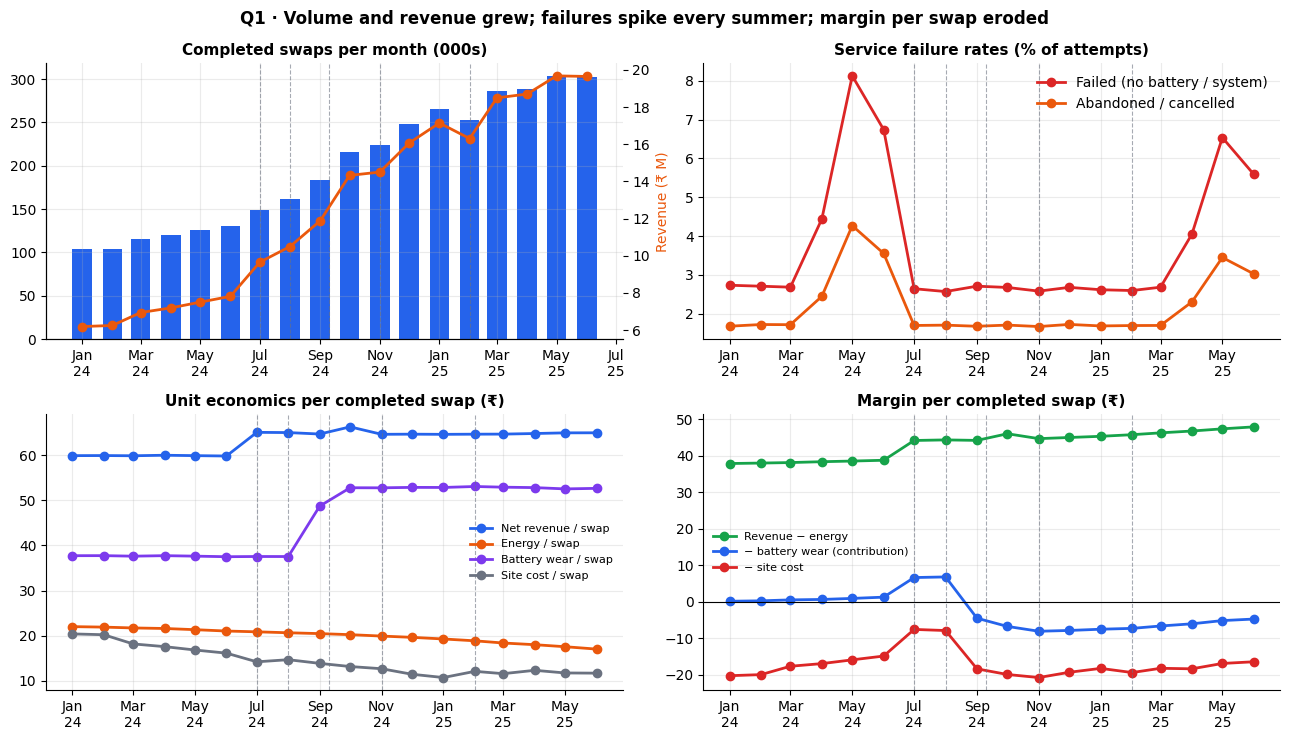

In [18]:
x = m["month"].to_list()
fig, axs = plt.subplots(2, 2, figsize=(13, 7.5))
ax = axs[0, 0]; ax.bar(x, (m["completed"] / 1000).to_list(), width=20, color=BLUE); ax.set_title("Completed swaps per month (000s)"); mark(ax)
a2 = ax.twinx(); a2.plot(x, (m["revenue"] / 1e6).to_list(), color=ORANGE, marker="o", lw=2); a2.set_ylabel("Revenue (₹ M)", color=ORANGE); a2.grid(False)
ax = axs[0, 1]
ax.plot(x, (m["fail_rate"] * 100).to_list(), color=RED, marker="o", lw=2, label="Failed (no battery / system)")
ax.plot(x, (m["abandon_rate"] * 100).to_list(), color=ORANGE, marker="o", lw=2, label="Abandoned / cancelled")
ax.set_title("Service failure rates (% of attempts)"); ax.legend(frameon=False); mark(ax)
ax = axs[1, 0]
for col, c, lab in [("rev_ps", BLUE, "Net revenue / swap"), ("energy_ps", ORANGE, "Energy / swap"), ("wear_ps", PURPLE, "Battery wear / swap"), ("site_ps", GREY, "Site cost / swap")]:
    ax.plot(x, m[col].to_list(), color=c, marker="o", lw=2, label=lab)
ax.set_title("Unit economics per completed swap (₹)"); ax.legend(frameon=False, fontsize=8); mark(ax)
ax = axs[1, 1]
for col, c, lab in [("gm_ps", GREEN, "Revenue − energy"), ("cm_ps", BLUE, "− battery wear (contribution)"), ("cm_site_ps", RED, "− site cost")]:
    ax.plot(x, m[col].to_list(), color=c, marker="o", lw=2, label=lab)
ax.axhline(0, color="black", lw=0.8); ax.set_title("Margin per completed swap (₹)"); ax.legend(frameon=False, fontsize=8); mark(ax)
for a in axs.flat: a.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%y"))
fig.suptitle("Q1 · Volume and revenue grew; failures spike every summer; margin per swap eroded", fontweight="bold")
fig.tight_layout(); fig.savefig("figs/q1_trends.png", bbox_inches="tight"); plt.show()

In [19]:
hy = m.with_columns(half=pl.when(pl.col("month") < date(2024, 7, 1)).then(pl.lit("2024H1")).when(pl.col("month") < date(2025, 1, 1)).then(pl.lit("2024H2")).otherwise(pl.lit("2025H1")))
hy.group_by("half").agg(pl.col("completed").sum(), pl.col("revenue").sum(), pl.col("energy").sum(), pl.col("wear").sum(), pl.col("contrib").sum()).with_columns(
    rev_ps=pl.col("revenue") / pl.col("completed"), energy_ps=pl.col("energy") / pl.col("completed"), wear_ps=pl.col("wear") / pl.col("completed"),
    contribution_ps=pl.col("contrib") / pl.col("completed")).sort("half")

half,completed,revenue,energy,wear,contrib,rev_ps,energy_ps,wear_ps,contribution_ps
str,u32,f64,f64,f64,f64,f64,f64,f64,f64
"""2024H1""",699830,4.1911e7,1.5095e7,2.6348e7,468839.607257,59.888097,21.569651,37.648513,0.669934
"""2024H2""",1183013,7.6944e7,2.3916e7,5.6982e7,-3.9540e6,65.04053,20.216234,48.166601,-3.342304
"""2025H1""",1698218,1.1000e8,3.0806e7,8.9641e7,-1.0447e7,64.773992,18.140394,52.78516,-6.151562


**Q1 findings: the metrics move in different directions**
- **Completed swaps and revenue grew about 3×.** Swaps went from 103k to 303k a month, and revenue from ₹6.2M to ₹19.7M a month.
- **The failure rate is seasonal, not trending.** It is about 2.6% outside summer and spikes every Apr–Jun (8.1% in May-24, 6.5% in May-25). Volume grew 2.4×, so absolute failures nearly doubled.
- **Contribution per swap turned negative:** ₹+0.7 in 2024H1, ₹−3.3 in 2024H2 and ₹−6.2 in 2025H1.
  - The Jul-24 price rise lifted it briefly.
  - From Sep-24, **battery wear per swap jumped from ₹37.6 to ₹52.8**, exactly when the new supplier's packs entered service (see Q4).
- **Energy per swap fell** (₹22 → ₹17). Degraded packs hold less energy, so riders get fewer km for each swap.

## 4 · Q2 & Q3 · Service failures, stations and geography

In [20]:
s = s.with_columns(season=pl.when(pl.col("month").dt.month().is_in([4, 5, 6])).then(pl.lit("Summer (Apr-Jun)")).otherwise(pl.lit("Rest of year")))
def rates(df, by):
    return df.group_by(by).agg(attempts=pl.len(), fail_pct=pl.col("failed").mean() * 100, stockout_pct=pl.col("stockout").mean() * 100,
                               abandon_pct=pl.col("abandoned").mean() * 100,
                               queue_median_s=pl.col("queue_wait_sec").filter(pl.col("completed")).median()).sort(by)
display(rates(s, ["city", "season"]).pivot(on="season", index="city", values="fail_pct"))
display(rates(s, ["vclass", "season"]))
display(rates(s, ["charger_generation", "season"]))
display(rates(s, ["location_type"]))

city,Rest of year,Summer (Apr-Jun)
str,f64,f64
"""Bengaluru""",2.640036,3.070096
"""Delhi NCR""",2.610643,8.370024
"""Hyderabad""",2.627623,7.094658
"""Jaipur""",2.611436,9.316638
"""Mumbai""",2.728856,2.723938
"""Pune""",2.702233,3.799344


vclass,season,attempts,fail_pct,stockout_pct,abandon_pct,queue_median_s
str,str,u32,f64,f64,f64,f64
"""2W""","""Rest of year""",2153797,2.27013,1.970381,1.50302,210.0
"""2W""","""Summer (Apr-Jun)""",1240418,5.430347,5.133995,2.945136,209.0
"""3W""","""Rest of year""",261784,5.77117,5.475507,3.281331,209.0
"""3W""","""Summer (Apr-Jun)""",153369,8.362185,8.040086,4.320951,210.0


charger_generation,season,attempts,fail_pct,stockout_pct,abandon_pct,queue_median_s
str,str,u32,f64,f64,f64,f64
"""Gen1""","""Rest of year""",1204879,2.634289,2.343721,1.694029,209.0
"""Gen1""","""Summer (Apr-Jun)""",614518,8.585428,8.283728,4.365373,210.0
"""Gen2""","""Rest of year""",1078738,2.66923,2.360165,1.699393,209.0
"""Gen2""","""Summer (Apr-Jun)""",539691,3.650422,3.354697,2.171798,209.0
"""Gen3""","""Rest of year""",131964,2.627989,2.328665,1.681519,210.0
"""Gen3""","""Summer (Apr-Jun)""",239578,3.224002,2.923474,1.925052,209.0


location_type,attempts,fail_pct,stockout_pct,abandon_pct,queue_median_s
str,u32,f64,f64,f64,f64
"""commercial_hub""",1533390,3.917725,3.627192,2.270133,210.0
"""highway_fuel_pump""",329308,3.210976,2.913989,1.906422,210.0
"""market""",1245168,3.948222,3.641517,2.296076,209.0
"""residential""",381706,3.427507,3.120202,2.028787,209.0
"""tech_park""",147368,3.273438,2.978259,1.944791,209.0
"""transit_hub""",172428,3.751711,3.438537,2.222957,209.0


In [21]:
# Telemetry: what happens to Gen1 / Gen2 / Gen3 cabinets as ambient temperature rises?
h = hourly.filter(pl.col("telemetry_status") == "ok").with_columns(temp_bin=(pl.col("ambient_temp_c") // 5 * 5))
tel = h.group_by("charger_generation", "temp_bin").agg(hours=pl.len(), avg_charge_min=pl.col("avg_charge_minutes").mean(),
        pct_hours_zero_2w_stock=(pl.col("charged_2w_min") == 0).mean() * 100).filter(pl.col("hours") > 500).sort("charger_generation", "temp_bin")
tel.pivot(on="charger_generation", index="temp_bin", values=["avg_charge_min", "pct_hours_zero_2w_stock"])

temp_bin,avg_charge_min_Gen1,avg_charge_min_Gen2,avg_charge_min_Gen3,pct_hours_zero_2w_stock_Gen1,pct_hours_zero_2w_stock_Gen2,pct_hours_zero_2w_stock_Gen3
f64,f64,f64,f64,f64,f64,f64
0.0,87.985011,64.052053,42.133008,0.334654,0.34656,0.0
5.0,87.984675,63.997961,42.039081,0.372149,0.333533,0.281613
10.0,87.995124,63.993745,42.005455,0.46068,0.296401,0.191859
15.0,87.999233,63.99653,41.991839,0.604487,0.373244,0.236611
20.0,87.98777,63.999014,42.051268,0.765951,0.477367,0.269753
25.0,88.025947,63.970523,41.994861,0.877125,0.45021,0.301794
30.0,90.986007,64.518108,42.088391,1.175957,0.50451,0.361488
35.0,117.873789,68.279342,42.762752,5.902075,0.756313,0.277713
40.0,163.692782,73.251075,43.530633,46.811737,1.033485,0.348432


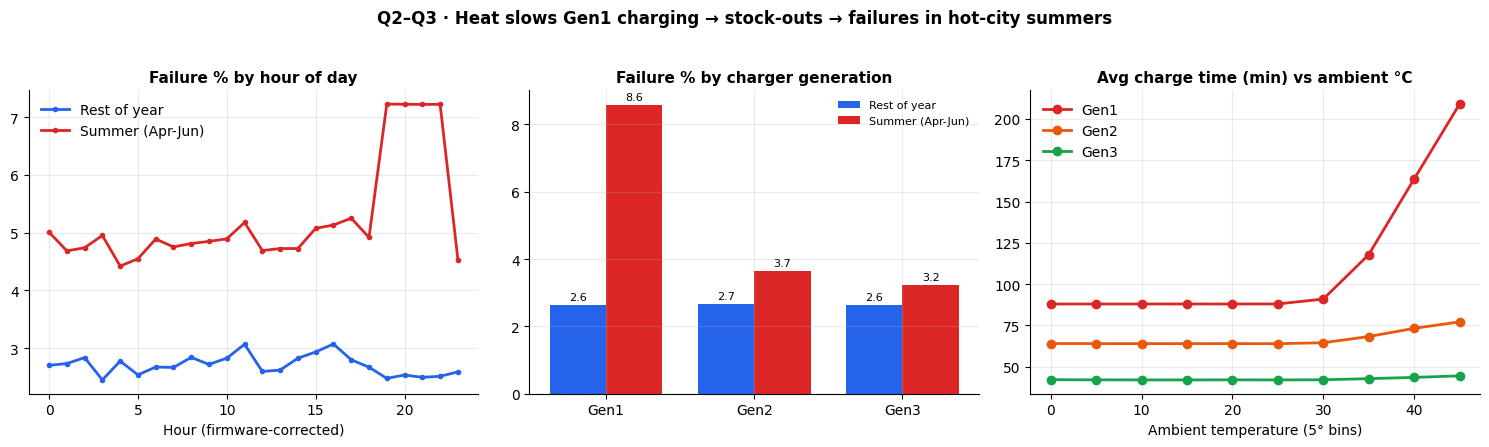

In [22]:
hr = rates(s, ["hour", "season"])
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axs[0]
for seas, c in [("Rest of year", BLUE), ("Summer (Apr-Jun)", RED)]:
    d = hr.filter(pl.col("season") == seas); ax.plot(d["hour"], d["fail_pct"], marker="o", ms=3, color=c, lw=2, label=seas)
ax.set_title("Failure % by hour of day"); ax.set_xlabel("Hour (firmware-corrected)"); ax.legend(frameon=False)
ax = axs[1]; g = rates(s, ["charger_generation", "season"]); gens = ["Gen1", "Gen2", "Gen3"]; xx = np.arange(3)
for i, (seas, c) in enumerate([("Rest of year", BLUE), ("Summer (Apr-Jun)", RED)]):
    v = [g.filter((pl.col("charger_generation") == q) & (pl.col("season") == seas))["fail_pct"].item() for q in gens]
    ax.bar(xx + (i - 0.5) * 0.38, v, 0.38, color=c, label=seas)
    for xi, vi in zip(xx + (i - 0.5) * 0.38, v): ax.text(xi, vi + 0.15, f"{vi:.1f}", ha="center", fontsize=8)
ax.set_xticks(xx, gens); ax.set_title("Failure % by charger generation"); ax.legend(frameon=False, fontsize=8)
ax = axs[2]
for q, c in zip(gens, [RED, ORANGE, GREEN]):
    d = tel.filter(pl.col("charger_generation") == q); ax.plot(d["temp_bin"], d["avg_charge_min"], marker="o", color=c, lw=2, label=q)
ax.set_title("Avg charge time (min) vs ambient °C"); ax.set_xlabel("Ambient temperature (5° bins)"); ax.legend(frameon=False)
fig.suptitle("Q2–Q3 · Heat slows Gen1 charging → stock-outs → failures in hot-city summers", fontweight="bold", y=1.03)
fig.tight_layout(); fig.savefig("figs/q2_failures.png", bbox_inches="tight"); plt.show()

In [23]:
HOT = ["Delhi NCR", "Jaipur", "Hyderabad"]
st_rates = rates(s, ["station_id"]).join(stations, on="station_id").with_columns(fails=pl.col("fail_pct") / 100 * pl.col("attempts")).sort("fails", descending=True)
cum = (st_rates["fails"].cum_sum() / st_rates["fails"].sum()).to_list()
print(f"Worst 10% of stations → {cum[len(cum)//10 - 1]:.0%} of failures; worst 20% → {cum[len(cum)//5 - 1]:.0%}")
summer_fails = s.filter(pl.col("failed") & (pl.col("season") == "Summer (Apr-Jun)"))
hotgen1 = summer_fails.filter((pl.col("charger_generation") == "Gen1") & pl.col("city").is_in(HOT)).height / summer_fails.height
print(f"Gen1 stations in hot cities: {stations.filter((pl.col('charger_generation') == 'Gen1') & pl.col('city').is_in(HOT)).height} → {hotgen1:.0%} of all summer failures")
st_rates.select("station_id", "city", "location_type", "charger_generation", "expansion_wave", "attempts", "fail_pct", "abandon_pct").head(12)

Worst 10% of stations → 25% of failures; worst 20% → 43%
Gen1 stations in hot cities: 36 → 58% of all summer failures


station_id,city,location_type,charger_generation,expansion_wave,attempts,fail_pct,abandon_pct
str,str,str,str,str,u32,f64,f64
"""STN-JAI-138""","""Jaipur""","""market""","""Gen1""","""Launch""",48857,5.700309,2.982172
"""STN-DEL-043""","""Delhi NCR""","""commercial_hub""","""Gen1""","""Launch""",49511,5.5624,3.063966
"""STN-HYD-072""","""Hyderabad""","""commercial_hub""","""Gen1""","""Launch""",51675,5.207547,2.87373
"""STN-DEL-050""","""Delhi NCR""","""commercial_hub""","""Gen1""","""Launch""",46976,5.634792,2.993018
"""STN-JAI-141""","""Jaipur""","""commercial_hub""","""Gen1""","""Launch""",45520,5.670035,3.075571
"""STN-JAI-137""","""Jaipur""","""commercial_hub""","""Gen1""","""Launch""",44303,5.638444,3.121685
"""STN-JAI-140""","""Jaipur""","""commercial_hub""","""Gen1""","""Launch""",44042,5.603742,2.872258
"""STN-HYD-070""","""Hyderabad""","""market""","""Gen1""","""Launch""",49617,4.972086,2.622085
"""STN-JAI-134""","""Jaipur""","""commercial_hub""","""Gen1""","""Launch""",42856,5.448479,2.979746


**Q2 & Q3 findings: failures are concentrated, and the mechanism is heat × charger generation**
- **Season × city:** in summer, Jaipur fails 9.3%, Delhi NCR 8.4% and Hyderabad 7.1%. Mumbai and Bengaluru barely move (about 3%). Outside summer, every city is about 2.6%.
- **Telemetry:** Gen1 charge time rises from 88 min below 30°C to **209 min at 45°C**. At that point there are zero charged 2W packs in 96% of hours. Gen2 and Gen3 barely change.
- **Concentration:** the **36 Gen1 stations in hot cities produce 58% of all summer failures**, and all 12 of the worst stations are Gen1 Launch sites in those cities.
- **3W riders** fail about 2.5× as often as 2W riders, because 3W stock-outs are more common.
- **Not drivers:**
  - Hour of day: the failure rate is flat across hours.
  - Queue wait: the median is about 209 s everywhere.
  - Location and host type, and connectivity.
- **Conclusion:** failures are a **charging-throughput** problem under heat, not a queueing or demand problem.

## 5 · Q4 · Battery and equipment performance

In [24]:
c2 = s.filter(pl.col("completed") & pl.col("km_valid") & (pl.col("vclass") == "2W")).with_columns(soh_bin=pl.col("soh_in_pct") // 5 * 5)
rng = c2.group_by("in_supplier", "soh_bin").agg(n=pl.len(), km=pl.col("km_since_last_swap").mean()).filter(pl.col("n") > 2000).sort("in_supplier", "soh_bin")
print("Correlation of pack SoH with km delivered (2W):", round(np.corrcoef(c2["soh_in_pct"].to_numpy(), c2["km_since_last_swap"].to_numpy())[0, 1], 3))

iss = s.filter("completed").group_by("battery_out_id").agg(issues=pl.len(), soh_first=pl.col("soh_out_pct").first(), soh_last=pl.col("soh_out_pct").last()).rename({"battery_out_id": "battery_id"})
bb = batteries.join(iss, on="battery_id", how="left").with_columns(soh_lost_per_100_swaps=(pl.col("soh_first") - pl.col("soh_last")) / pl.col("issues") * 100)
cohort = bb.group_by("supplier", "pack_type").agg(packs=pl.len(), first_commissioned=pl.col("commission_date").min(), soh_lost_per_100_swaps=pl.col("soh_lost_per_100_swaps").median(),
                                                  current_soh=pl.col("current_soh_pct").mean(), retired_share=pl.col("retired_date").is_not_null().mean()).sort("pack_type", "supplier")
display(cohort)
display(bb.filter(pl.col("pack_type") == "2W_2.1kWh").group_by("supplier", "manufacturing_lot").agg(packs=pl.len(), soh_lost_per_100=pl.col("soh_lost_per_100_swaps").median())
        .sort("soh_lost_per_100", descending=True).head(6))
display(bb.group_by("bms_firmware").agg(soh_lost_per_100=pl.col("soh_lost_per_100_swaps").median()))

Correlation of pack SoH with km delivered (2W): 0.707


supplier,pack_type,packs,first_commissioned,soh_lost_per_100_swaps,current_soh,retired_share
str,str,u32,date,f64,f64,f64
"""Amptek""","""2W_2.1kWh""",1098,2024-03-01,2.984243,79.956648,0.0
"""Cellora""","""2W_2.1kWh""",3035,2023-03-01,2.984127,79.970675,0.0
"""Kyron""","""2W_2.1kWh""",1385,2024-09-10,9.59596,60.532274,1.0
"""Amptek""","""3W_4.8kWh""",209,2024-03-01,3.333333,86.513876,0.0
"""Cellora""","""3W_4.8kWh""",520,2023-03-01,3.350854,86.5225,0.0
"""Kyron""","""3W_4.8kWh""",253,2024-07-01,3.529412,81.348221,0.209486


supplier,manufacturing_lot,packs,soh_lost_per_100
str,str,u32,f64
"""Kyron""","""KY-2408""",471,9.622166
"""Kyron""","""KY-2409""",462,9.588689
"""Kyron""","""KY-2407""",452,9.587864
"""Amptek""","""AM-2506""",38,3.058941
"""Amptek""","""AM-2405""",76,3.049568
"""Amptek""","""AM-2408""",74,3.025817


bms_firmware,soh_lost_per_100
str,f64
"""BMS-4.2""",3.100775
"""BMS-4.1""",3.127889
"""BMS-4.0""",3.096677


In [25]:
kyron_m = s.filter(pl.col("completed") & (pl.col("vclass") == "2W")).group_by("month").agg(
    kyron_share=(pl.col("out_supplier") == "Kyron").mean(), kyron_soh_out=pl.col("soh_out_pct").filter(pl.col("out_supplier") == "Kyron").mean(),
    km_per_pack=pl.col("km_since_last_swap").mean(), swaps_per_rider=pl.len() / pl.col("rider_id").n_unique()).sort("month")
display(kyron_m)
tm = tickets.with_columns(month=pl.col("created_ts").dt.truncate("1mo").dt.date()).group_by("month").agg(
    agent_label=(pl.col("category") == "low_range").sum(), relabelled=(pl.col("category_fixed") == "battery_range").sum()).sort("month") \
    .join(s.filter("completed").group_by("month").len("swaps"), on="month").with_columns(
    agent_per10k=pl.col("agent_label") / pl.col("swaps") * 1e4, relabelled_per10k=pl.col("relabelled") / pl.col("swaps") * 1e4)
kw = s.filter(pl.col("completed") & (pl.col("vclass") == "2W")).group_by(pl.col("out_supplier") == "Kyron").agg(wear_per_swap=pl.col("wear_cost").mean())
print("Wear cost per 2W swap (Kyron=true):", kw.to_dicts())
after = s.filter(pl.col("completed") & (pl.col("out_supplier") == "Kyron") & (pl.col("vclass") == "2W") & (pl.col("date") >= date(2025, 6, 15))).height
print(f"ANOMALY: Kyron 2W packs are recorded as retired on 2025-06-15, yet were issued {after:,} times after that date")

month,kyron_share,kyron_soh_out,km_per_pack,swaps_per_rider
date,f64,f64,f64,f64
2024-01-01,0.0,null,70.50951,25.67449
2024-02-01,0.0,null,70.075166,24.396102
2024-03-01,0.0,null,69.555931,25.417877
2024-04-01,0.0,null,68.3026,24.444572
2024-05-01,0.0,null,65.448863,23.700871
2024-06-01,0.0,null,66.121571,23.239944
2024-07-01,0.0,null,66.894548,24.847614
2024-08-01,0.0,null,66.232531,24.907644
2024-09-01,0.180839,98.166258,61.927084,26.483411


Wear cost per 2W swap (Kyron=true): [{'out_supplier': False, 'wear_per_swap': 31.910048750741066}, {'out_supplier': True, 'wear_per_swap': 102.83316480493548}]
ANOMALY: Kyron 2W packs are recorded as retired on 2025-06-15, yet were issued 35,105 times after that date


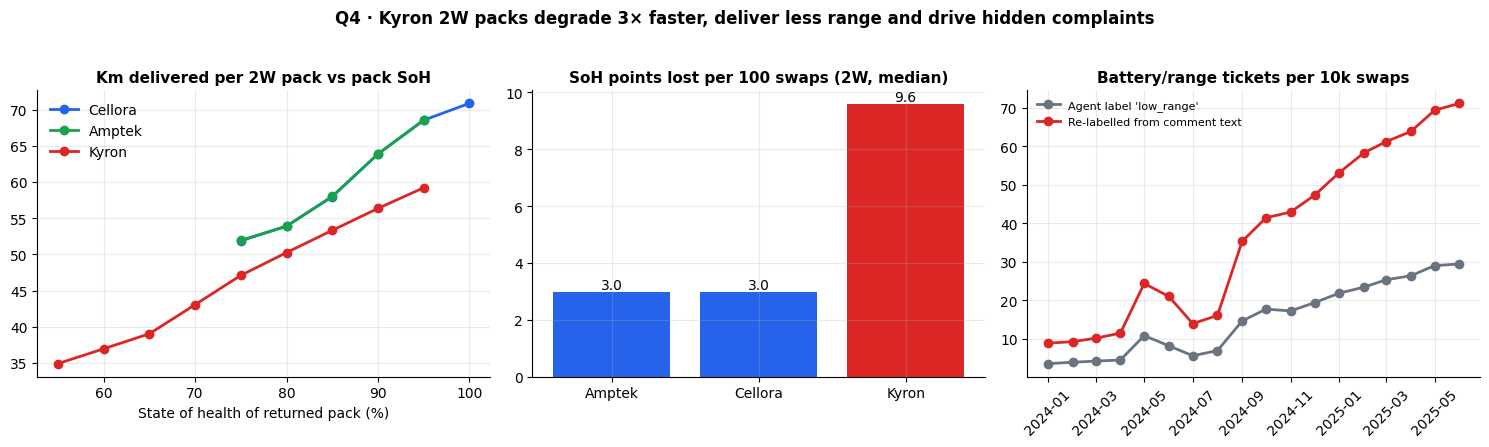

In [26]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axs[0]
for sup, col in [("Cellora", BLUE), ("Amptek", GREEN), ("Kyron", RED)]:
    d = rng.filter(pl.col("in_supplier") == sup); ax.plot(d["soh_bin"], d["km"], marker="o", color=col, lw=2, label=sup)
ax.set_title("Km delivered per 2W pack vs pack SoH"); ax.set_xlabel("State of health of returned pack (%)"); ax.legend(frameon=False)
ax = axs[1]; cc = cohort.filter(pl.col("pack_type") == "2W_2.1kWh")
ax.bar(cc["supplier"], cc["soh_lost_per_100_swaps"], color=[RED if q == "Kyron" else BLUE for q in cc["supplier"]])
for i, v in enumerate(cc["soh_lost_per_100_swaps"]): ax.text(i, v + 0.1, f"{v:.1f}", ha="center")
ax.set_title("SoH points lost per 100 swaps (2W, median)")
ax = axs[2]
ax.plot(tm["month"], tm["agent_per10k"], color=GREY, marker="o", lw=2, label="Agent label 'low_range'")
ax.plot(tm["month"], tm["relabelled_per10k"], color=RED, marker="o", lw=2, label="Re-labelled from comment text")
ax.set_title("Battery/range tickets per 10k swaps"); ax.legend(frameon=False, fontsize=8); ax.tick_params(axis="x", rotation=45)
fig.suptitle("Q4 · Kyron 2W packs degrade 3× faster, deliver less range and drive hidden complaints", fontweight="bold", y=1.03)
fig.tight_layout(); fig.savefig("figs/q4_battery.png", bbox_inches="tight"); plt.show()

**Q4 findings: one supplier cohort stands out**
- **The Kyron 2W cohort** is three lots (KY-2407/08/09) of 1,385 packs, all commissioned on 10 Sep 2024. It loses **9.6 health points per 100 swaps**, against 3.0 for Cellora and Amptek. Every other lot sits between 2.94 and 3.06.
  - Kyron's 3W packs and the BMS firmware versions show no such gap.
- **Range follows health** (r = 0.71), and Kyron delivers fewer km even at the same health level. Kyron is about 25% of 2W packs issued, and their average health fell from 98% to 63%.
- **Network km per 2W pack fell 32%** (70.5 → 48). Riders swap more often as a result, which adds load on the cabinets.
- **Hidden complaints:** after re-labelling the comments, battery/range tickets per 10k swaps rose **8×** (8.8 → 71). The agent labels alone understate this by more than half.
- **Wear cost:** about **₹103 per Kyron swap against ₹32** for other 2W packs. This is the main driver of the margin erosion in Q1.
- **Anomaly:** Kyron packs are marked retired on 15 Jun 2025 but were still issued about 35k times afterwards. The asset ledger and cabinet allocation are out of sync.

## 6 · Q5 · Pricing and partner economics

In [27]:
PEAK_H, OFF_H = [12, 13, 19, 20, 21], [23, 0, 1, 2, 3, 4, 5, 14, 15, 16]
s = s.with_columns(pilot_city=pl.col("city").is_in(["Bengaluru", "Pune"]),
                   band=pl.when(pl.col("hour").is_in(PEAK_H)).then(pl.lit("peak")).when(pl.col("hour").is_in(OFF_H)).then(pl.lit("offpeak")).otherwise(pl.lit("shoulder")))
display(s.filter(pl.col("tariff_code").is_in(["PEAK", "OFFPEAK"])).group_by("city", "tariff_code").agg(first=pl.col("date").min(), n=pl.len()).sort("city"))
display(s.filter("completed").group_by("vclass", "tariff_code", (pl.col("date") >= date(2024, 7, 1)).alias("after_jul24")).agg(
    list_price=pl.col("list_price_inr").mean(), charged=pl.col("amount_charged_inr").mean()).sort("vclass", "tariff_code", "after_jul24"))

city,tariff_code,first,n
str,str,date,u32
"""Bengaluru""","""OFFPEAK""",2024-10-01,20955
"""Bengaluru""","""PEAK""",2024-10-01,98363
"""Pune""","""PEAK""",2024-10-01,73116
"""Pune""","""OFFPEAK""",2024-10-01,15422


vclass,tariff_code,after_jul24,list_price,charged
str,str,bool,f64,f64
"""2W""","""OFFPEAK""",true,65.0,57.002735
"""2W""","""PARTNER""",false,60.0,53.534505
"""2W""","""PARTNER""",true,65.0,57.062485
"""2W""","""PEAK""",true,65.0,80.000291
"""2W""","""STD""",false,60.0,60.00052
"""2W""","""STD""",true,65.0,64.999832
"""3W""","""OFFPEAK""",true,110.0,102.002607
"""3W""","""PARTNER""",false,100.0,90.964058
"""3W""","""PARTNER""",true,110.0,99.163405


**Base price change (Jul-24).** Did usage per rider drop after the ₹5 increase?

In [28]:
s.filter("completed").group_by("segment", "month").agg(swaps_per_active_rider=pl.len() / pl.col("rider_id").n_unique()).filter(
    pl.col("month").is_between(date(2024, 4, 1), date(2024, 10, 1))).pivot(on="segment", index="month", values="swaps_per_active_rider").sort("month")

month,independent,fleet
date,f64,f64
2024-04-01,20.65598,25.533762
2024-05-01,20.107227,24.63244
2024-06-01,19.727633,24.160483
2024-07-01,21.227874,25.848775
2024-08-01,21.325653,25.825049
2024-09-01,22.483054,27.305154
2024-10-01,24.050658,29.24484


**Peak/off-peak pilot: difference-in-differences.** The pilot ran in Bengaluru and Pune from Oct 2024 and applied to independent riders only.
- **Treatment:** independents in the pilot cities.
- **Control:** independents in the other four cities.
- **Periods:** Jul–Sep 2024 against Oct 2024–Mar 2025. Summer is excluded to keep the seasonal failure spike out.

In [29]:
ind = s.filter((pl.col("segment") == "independent") & pl.col("completed") & pl.col("date").is_between(date(2024, 7, 1), date(2025, 3, 31))).with_columns(post=pl.col("date") >= date(2024, 10, 1))
did = ind.group_by("pilot_city", "post").agg(peak_share=(pl.col("band") == "peak").mean() * 100, offpeak_share=(pl.col("band") == "offpeak").mean() * 100,
                                             revenue_per_swap=pl.col("revenue").mean(), n=pl.len()).sort("pilot_city", "post")
display(did)
g = lambda pc, po, col: did.filter((pl.col("pilot_city") == pc) & (pl.col("post") == po))[col].item()
for col in ["peak_share", "offpeak_share", "revenue_per_swap"]:
    print(f"DiD {col:18s}: {(g(True, True, col) - g(True, False, col)) - (g(False, True, col) - g(False, False, col)):+.2f}")
svc = s.filter(pl.col("date").is_between(date(2024, 7, 1), date(2025, 3, 31)) & (pl.col("band") == "peak")).with_columns(post=pl.col("date") >= date(2024, 10, 1))
display(svc.group_by("pilot_city", "post").agg(peak_hour_fail_pct=pl.col("failed").mean() * 100).sort("pilot_city", "post"))

pilot_city,post,peak_share,offpeak_share,revenue_per_swap,n
bool,bool,f64,f64,f64,u32
false,false,59.891735,10.087795,67.407178,109915
false,true,59.773191,10.37728,67.366053,335878
true,false,60.192442,9.915619,67.453891,59966
true,true,57.44467,12.639132,75.341792,170162


DiD peak_share        : -2.63
DiD offpeak_share     : +2.43
DiD revenue_per_swap  : +7.93


pilot_city,post,peak_hour_fail_pct
bool,bool,f64
false,false,2.539199
false,true,2.523464
true,false,2.521992
true,true,2.560574


**Fleet partner economics**: revenue alone hides large differences in contribution.

In [30]:
fs = s.filter(pl.col("completed") & (pl.col("segment") == "fleet"))
pe = fs.group_by("partner_id").agg(swaps=pl.len(), revenue=pl.col("revenue").sum(), list_rev=pl.col("list_price_inr").sum(),
                                   energy=pl.col("energy_cost").sum(), wear=pl.col("wear_cost").sum()).join(partners, on="partner_id").with_columns(
    share_of_fleet_swaps=pl.col("swaps") / pl.col("swaps").sum() * 100, effective_discount=(1 - pl.col("revenue") / pl.col("list_rev")) * 100,
    rev_per_swap=pl.col("revenue") / pl.col("swaps"), contribution_per_swap=(pl.col("revenue") - pl.col("energy") - pl.col("wear")) / pl.col("swaps"),
    contribution_total=pl.col("revenue") - pl.col("energy") - pl.col("wear")).sort("swaps", descending=True)
indep_cm = s.filter(pl.col("completed") & (pl.col("segment") == "independent"))["contribution"].mean()
print(f"Independent riders: contribution per swap ₹{indep_cm:.1f}")
pe.select("partner_name", "partner_segment", "discount_pct", "discount_pct_after_amendment", "peak_surcharge_billable", "payment_terms_days",
          "share_of_fleet_swaps", "effective_discount", "rev_per_swap", "contribution_per_swap", "contribution_total")

Independent riders: contribution per swap ₹3.6


partner_name,partner_segment,discount_pct,discount_pct_after_amendment,peak_surcharge_billable,payment_terms_days,share_of_fleet_swaps,effective_discount,rev_per_swap,contribution_per_swap,contribution_total
str,str,f64,f64,str,i64,f64,f64,f64,f64,f64
"""ZipDrop""","""quick_commerce""",12.0,28.0,"""N""",45,23.178747,21.921346,52.074122,-13.52002,-7.4079e6
"""FeastFly""","""food_delivery""",10.0,null,"""Y""",30,21.803854,6.625003,62.026482,-2.387378,-1.2305e6
"""ParcelNest""","""ecom_logistics""",15.0,null,"""Y""",30,12.518032,14.749308,56.51632,-8.122674,-2.4036e6
"""Swiggle Go""","""food_delivery""",11.0,null,"""N""",30,10.03501,10.998988,59.306332,-5.245892,-1.2444e6
"""CargoTuk""","""cargo_3w""",8.0,null,"""Y""",30,5.551476,7.888342,99.46053,-25.118925,-3.2964e6
"""QuickCart""","""quick_commerce""",9.0,null,"""Y""",30,5.401173,5.763751,62.006955,-1.152004,-147085.623708
"""RideMitra""","""bike_taxi""",6.0,null,"""Y""",15,5.045785,4.965252,62.71734,-1.42859,-170397.96886
"""DabbaXpress""","""food_delivery""",8.0,null,"""Y""",30,3.886173,4.345568,63.609599,-1.023789,-94050.34047
"""UrbanErrand""","""bike_taxi""",5.0,null,"""Y""",15,3.47799,3.983057,63.466585,-0.706878,-58116.656655


ZipDrop: revenue given up by moving 12% → 28% discount (Nov-24 to Jun-25): ₹3.6M


ZipDrop before Nov-24: revenue/swap ₹57.5, contribution/swap ₹-2.7
ZipDrop after  Nov-24: revenue/swap ₹48.6, contribution/swap ₹-20.4


month,swaps,rev_ps,gm_ps,cm_ps
date,u32,f64,f64,f64
2024-07-01,21684,60.023815,39.383207,3.772827
2024-08-01,24605,59.870652,39.533561,4.162667
2024-09-01,28421,59.542331,39.418695,-7.79017
2024-10-01,33224,59.469582,39.592583,-11.562147
2024-11-01,34853,48.631492,29.06306,-22.10726
2024-12-01,38976,48.698071,29.343913,-21.612632
2025-01-01,41900,48.622711,29.687203,-21.106162
2025-02-01,39374,48.691492,30.120908,-21.319737
2025-03-01,44746,48.720453,30.579493,-20.523995


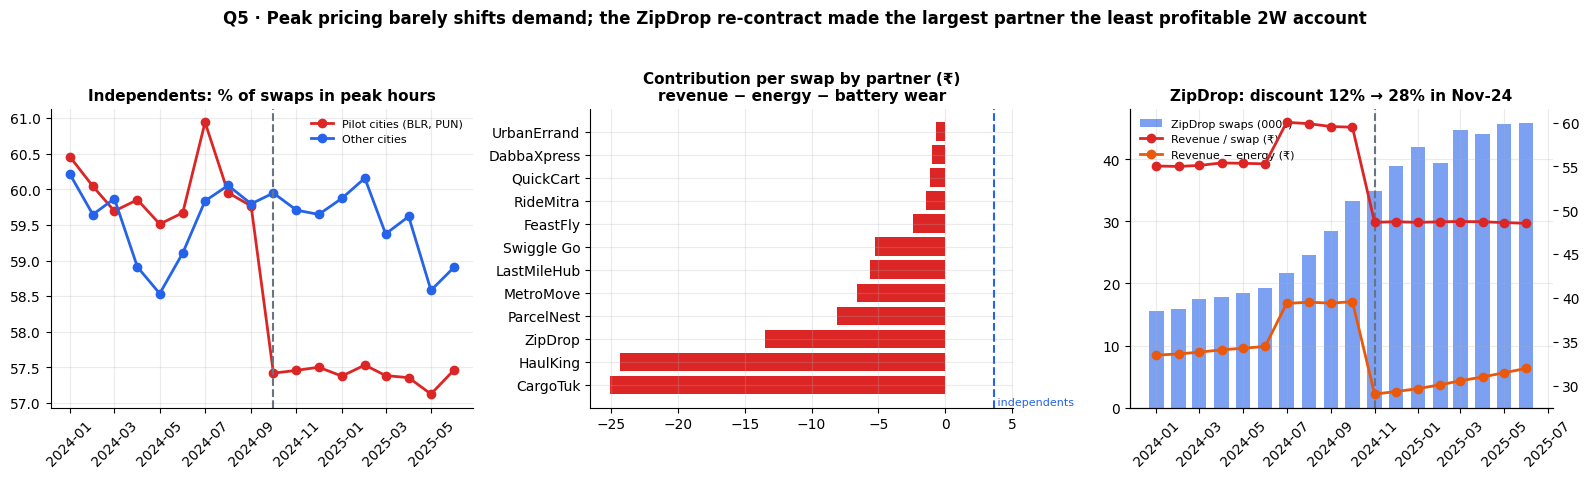

In [31]:
zd = s.filter(pl.col("completed") & (pl.col("partner_id") == "FP-03")).group_by("month").agg(swaps=pl.len(), rev_ps=pl.col("revenue").mean(),
        gm_ps=(pl.col("revenue") - pl.col("energy_cost")).mean(), cm_ps=pl.col("contribution").mean()).sort("month")
given_up = s.filter(pl.col("completed") & (pl.col("partner_id") == "FP-03") & (pl.col("date") >= date(2024, 11, 1))).select((pl.col("list_price_inr") * 0.16).sum()).item()
print(f"ZipDrop: revenue given up by moving 12% → 28% discount (Nov-24 to Jun-25): ₹{given_up/1e6:.1f}M")
zp = s.filter(pl.col("completed") & (pl.col("partner_id") == "FP-03")).with_columns(after_nov24=pl.col("date") >= date(2024, 11, 1))
for after in [False, True]:
    g_ = zp.filter(pl.col("after_nov24") == after)
    print(f"ZipDrop {'after ' if after else 'before'} Nov-24: revenue/swap ₹{g_['revenue'].mean():.1f}, contribution/swap ₹{g_['contribution'].mean():.1f}")
display(zd.filter(pl.col("month") >= date(2024, 7, 1)))
ps = s.filter((pl.col("segment") == "independent") & pl.col("completed")).group_by("month", "pilot_city").agg(peak_share=(pl.col("band") == "peak").mean() * 100).sort("month")

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
ax = axs[0]
for pc, c, lab in [(True, RED, "Pilot cities (BLR, PUN)"), (False, BLUE, "Other cities")]:
    d = ps.filter(pl.col("pilot_city") == pc); ax.plot(d["month"], d["peak_share"], marker="o", color=c, lw=2, label=lab)
ax.axvline(date(2024, 10, 1), color=GREY, ls="--"); ax.set_title("Independents: % of swaps in peak hours"); ax.legend(frameon=False, fontsize=8); ax.tick_params(axis="x", rotation=45)
ax = axs[1]; pp = pe.sort("contribution_per_swap")
ax.barh(pp["partner_name"], pp["contribution_per_swap"], color=[RED if v < 0 else GREEN for v in pp["contribution_per_swap"]])
ax.axvline(indep_cm, color=BLUE, ls="--"); ax.text(indep_cm, -0.9, " independents", color=BLUE, fontsize=8)
ax.set_title("Contribution per swap by partner (₹)\nrevenue − energy − battery wear")
ax = axs[2]
ax.bar(zd["month"], zd["swaps"] / 1000, width=20, color=BLUE, alpha=0.6, label="ZipDrop swaps (000s)")
a2 = ax.twinx(); a2.grid(False)
a2.plot(zd["month"], zd["rev_ps"], color=RED, marker="o", lw=2, label="Revenue / swap (₹)"); a2.plot(zd["month"], zd["gm_ps"], color=ORANGE, marker="o", lw=2, label="Revenue − energy (₹)")
ax.axvline(date(2024, 11, 1), color=GREY, ls="--"); ax.set_title("ZipDrop: discount 12% → 28% in Nov-24"); ax.tick_params(axis="x", rotation=45)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Q5 · Peak pricing barely shifts demand; the ZipDrop re-contract made the largest partner the least profitable 2W account", fontweight="bold", y=1.03)
fig.tight_layout(); fig.savefig("figs/q5_pricing.png", bbox_inches="tight"); plt.show()

**Q5 findings**
- **Base price +₹5 (Jul-24):** there was no visible demand loss. Swaps per active rider kept rising for both segments.
- **Peak pilot:**
  - The DiD shows only **−2.6 points of peak-hour share** for independents and +2.4 points off-peak.
  - **Revenue per swap rose ₹7.9.** Peak-hour failure rates were unchanged.
  - **Conclusion:** the pilot is a **revenue lever, not a congestion fix**. It also ran in the two cities that had the *fewest* heat failures.
- **Partners:** every fleet partner is contribution-negative once battery wear is counted. Independents are about +₹3.6 per swap.
  - **ZipDrop** is the largest partner (23% of fleet swaps). Its discount went from 12% to **28%**, it pays no peak surcharge and it has 45-day payment terms. Contribution fell from about −₹8 (Sep-24) to **−₹22 per swap in Nov-24**, and has averaged about −₹20 since, and the extra discount gave away about ₹3.6M in 8 months.
  - **3W partners** CargoTuk and HaulKing lose about ₹25 per swap because large-pack wear is expensive.
- **Segments are affected differently:** independents face the price rise and the peak surcharge, while partner-billed riders are shielded by their contract terms. Two partners are exempt from the surcharge altogether.

## 7 · Q6 · Root cause of new-rider churn
**Setup:**
- **Cohort:** riders whose first attempt falls between Feb 2024 and Apr 2025. Jan 2024 is excluded because those riders may have started before the data begins.
- **Outcome:** "retained" means a completed swap in **days 30–60** after the first attempt.
- **Features:** the rider's experience in their **first 30 days**.

Riders who swap more both experience more failures *and* are more likely to stay, so raw counts are confounded. We therefore use failure **rates** and control for activity level.

In [32]:
first = s.group_by("rider_id").agg(first_ts=pl.col("event_ts").min())
s2 = s.join(first, on="rider_id").with_columns(day=(pl.col("event_ts") - pl.col("first_ts")).dt.total_days())
new = first.filter(pl.col("first_ts").dt.date().is_between(date(2024, 2, 1), date(2025, 4, 30)))
w30 = s2.filter(pl.col("day") < 30).join(new.select("rider_id"), on="rider_id")
feat = w30.group_by("rider_id").agg(
    attempts_30=pl.len(), fails_30=pl.col("failed").sum(), abandons_30=pl.col("abandoned").sum(),
    q_wait_30=pl.col("queue_wait_sec").filter(pl.col("completed")).mean(), kyron_share_30=(pl.col("out_supplier") == "Kyron").mean(),
    km_per_pack_30=pl.col("km_since_last_swap").mean(), price_paid_30=pl.col("amount_charged_inr").filter(pl.col("completed")).mean(),
    main_station=pl.col("station_id").mode().first(), city=pl.col("city").mode().first(), first_date=pl.col("date").min())
ret = s2.join(new.select("rider_id"), on="rider_id").group_by("rider_id").agg(
    retained=((pl.col("day") >= 30) & (pl.col("day") < 60) & pl.col("completed")).any(),
    active_60_90=((pl.col("day") >= 60) & (pl.col("day") < 90) & pl.col("completed")).any())
tk = tickets.join(new, on="rider_id").filter((pl.col("created_ts") - pl.col("first_ts")).dt.total_days() < 30).group_by("rider_id").agg(
    unresolved_30=(pl.col("resolution_status") == "unresolved").sum(), range_ticket_30=(pl.col("category_fixed") == "battery_range").sum())
promo = city_daily.select("city", pl.col("date").alias("d"), "competitor_promo_active")
df = (feat.join(ret, on="rider_id").join(tk, on="rider_id", how="left")
      .join(riders.select("rider_id", "vehicle_class", "segment", "partner_name"), on="rider_id", how="left")
      .join(stations.select(pl.col("station_id").alias("main_station"), pl.col("charger_generation").alias("main_gen"), pl.col("competitor_within_1_5km_since").alias("comp_since")), on="main_station", how="left")
      .with_columns(pl.col(["unresolved_30", "range_ticket_30"]).fill_null(0),
                    competitor_nearby=pl.col("comp_since").is_not_null() & (pl.col("comp_since") <= pl.col("first_date")),
                    fail_rate_30=(pl.col("fails_30") + pl.col("abandons_30")) / pl.col("attempts_30")))
pd_ = df.select("rider_id", "city", "first_date").with_columns(d=pl.date_ranges("first_date", pl.col("first_date") + timedelta(days=29))).explode("d") \
       .join(promo, on=["city", "d"], how="left").group_by("rider_id").agg(promo_days_30=pl.col("competitor_promo_active").sum())
df = df.join(pd_, on="rider_id", how="left")
print(f"New riders: {df.height:,} | retained (days 30–60): {df['retained'].mean():.1%} | active days 60–90: {df['active_60_90'].mean():.1%}")
df.group_by(pl.col("first_date").dt.truncate("1q").alias("cohort_quarter")).agg(n=pl.len(), retained_pct=pl.col("retained").mean() * 100,
    first_month_fail_pct=pl.col("fail_rate_30").mean() * 100, km_per_pack=pl.col("km_per_pack_30").mean()).sort("cohort_quarter")

New riders: 13,215 | retained (days 30–60): 85.4% | active days 60–90: 80.0%


cohort_quarter,n,retained_pct,first_month_fail_pct,km_per_pack
date,u32,f64,f64,f64
2024-01-01,1168,86.900685,5.246151,74.202673
2024-04-01,2094,81.709647,9.662345,70.734728
2024-07-01,2529,87.030447,4.768814,68.597552
2024-10-01,3270,86.360856,4.69216,63.144269
2025-01-01,3046,86.309915,4.922913,60.032441
2025-04-01,1108,81.6787,8.125511,55.58396


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
NAMES = {"fail_rate_30": "Failure rate, first 30 days", "km10": "Km per pack (per 10 km)", "kyron": "Share of Kyron packs", "range_ticket": "Raised range ticket",
         "unresolved": "Unresolved ticket", "independent": "Independent (vs fleet)", "price10": "Price paid (per ₹10)", "is_3w": "3W vehicle",
         "gen1": "Main station is Gen1", "comp": "Competitor nearby", "promo": "Competitor promo days", "qmin": "Queue wait (min)", "log_att": "Activity level (control)"}
def fit(outcome, data):
    X = data.with_columns(log_att=pl.col("attempts_30").log(), independent=(pl.col("segment") == "independent").cast(pl.Float64),
                          is_3w=(pl.col("vehicle_class") == "3W").cast(pl.Float64), gen1=(pl.col("main_gen") == "Gen1").cast(pl.Float64),
                          comp=pl.col("competitor_nearby").cast(pl.Float64), km10=pl.col("km_per_pack_30") / 10, kyron=pl.col("kyron_share_30"),
                          unresolved=(pl.col("unresolved_30") > 0).cast(pl.Float64), range_ticket=(pl.col("range_ticket_30") > 0).cast(pl.Float64),
                          price10=pl.col("price_paid_30") / 10, qmin=pl.col("q_wait_30") / 60, promo=pl.col("promo_days_30").cast(pl.Float64)
                         ).drop_nulls(["km_per_pack_30", "price_paid_30", "q_wait_30"])
    cols = list(NAMES)
    Xm = X.select(cols).to_numpy().astype(float); y = X[outcome].to_numpy().astype(int)
    lr = LogisticRegression(C=1e6, max_iter=5000).fit(Xm, y); p = lr.predict_proba(Xm)[:, 1]
    Xd = np.column_stack([np.ones(len(Xm)), Xm]); se = np.sqrt(np.diag(np.linalg.inv(Xd.T @ (Xd * (p * (1 - p))[:, None]))))[1:]
    res = pl.DataFrame({"feature": [NAMES[c] for c in cols], "odds_ratio": np.exp(lr.coef_[0]), "z": lr.coef_[0] / se,
                        "effect_per_1SD": lr.coef_[0] * Xm.std(0)}).sort(pl.col("effect_per_1SD").abs(), descending=True)
    print(f"{outcome}: n={len(y):,}, base rate {y.mean():.1%}, AUC {roc_auc_score(y, p):.3f}")
    return res
res = fit("retained", df); display(res)
display(fit("active_60_90", df.filter(pl.col("first_date") <= date(2025, 3, 31))))   # robustness: later outcome window

retained: n=13,213, base rate 85.4%, AUC 0.893


feature,odds_ratio,z,effect_per_1SD
str,f64,f64,f64
"""Activity level (control)""",24.905324,38.671448,1.696142
"""Km per pack (per 10 km)""",1.598547,9.270815,0.639738
"""Failure rate, first 30 days""",0.001506,-13.560239,-0.421106
"""Independent (vs fleet)""",1.991781,7.628367,0.33545
"""3W vehicle""",0.425093,-2.394647,-0.301146
"""Price paid (per ₹10)""",1.151126,2.109197,0.219969
"""Competitor nearby""",1.878575,2.138588,0.081753
"""Competitor promo days""",1.013115,1.773012,0.066249
"""Main station is Gen1""",0.883876,-1.923295,-0.061717


active_60_90: n=12,105, base rate 80.5%, AUC 0.742


feature,odds_ratio,z,effect_per_1SD
str,f64,f64,f64
"""Activity level (control)""",4.93186,30.382375,0.84282
"""Km per pack (per 10 km)""",1.241756,5.059366,0.288432
"""Failure rate, first 30 days""",0.01892,-9.896443,-0.253039
"""Independent (vs fleet)""",1.630181,6.845227,0.238008
"""3W vehicle""",0.733316,-1.077867,-0.109105
"""Price paid (per ₹10)""",1.04149,0.770523,0.063231
"""Queue wait (min)""",0.920498,-1.862491,-0.046418
"""Main station is Gen1""",0.914066,-1.757299,-0.044921
"""Competitor nearby""",1.433498,1.476907,0.041001


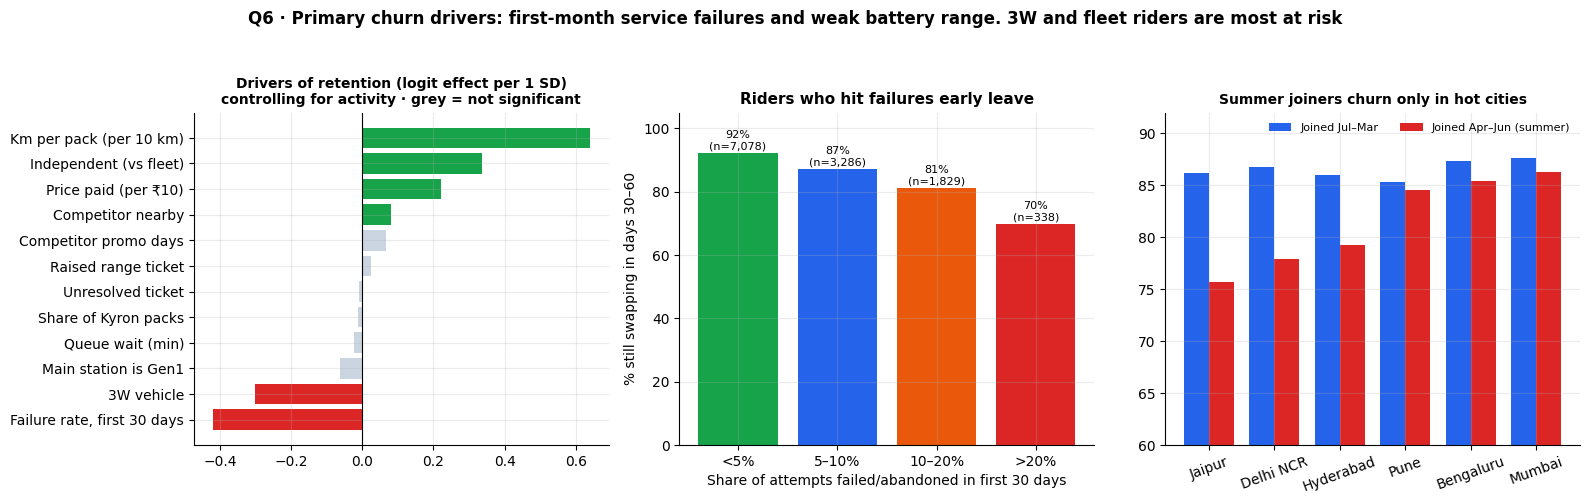

In [34]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axs[0]; rr = res.filter(pl.col("feature") != "Activity level (control)").sort("effect_per_1SD"); sig = (rr["z"].abs() > 1.96).to_list()
ax.barh(rr["feature"], rr["effect_per_1SD"], color=[(RED if v < 0 else GREEN) if q else "#cbd5e1" for v, q in zip(rr["effect_per_1SD"], sig)])
ax.axvline(0, color="black", lw=0.8); ax.set_title("Drivers of retention (logit effect per 1 SD)\ncontrolling for activity · grey = not significant", fontsize=10)
ax = axs[1]
a = df.filter(pl.col("attempts_30") >= 10).with_columns(f=pl.col("fail_rate_30").cut([0.05, 0.1, 0.2], labels=["<5%", "5–10%", "10–20%", ">20%"])).group_by("f").agg(
    ret=pl.col("retained").mean() * 100, n=pl.len(), o=pl.col("fail_rate_30").min()).sort("o")
ax.bar([str(q) for q in a["f"]], a["ret"], color=[GREEN, BLUE, ORANGE, RED])
for i, (v, n) in enumerate(zip(a["ret"], a["n"])): ax.text(i, v + 1, f"{v:.0f}%\n(n={n:,})", ha="center", fontsize=8)
ax.set_ylim(0, 105); ax.set_xlabel("Share of attempts failed/abandoned in first 30 days"); ax.set_ylabel("% still swapping in days 30–60"); ax.set_title("Riders who hit failures early leave")
ax = axs[2]
cs = df.with_columns(summer=pl.col("first_date").dt.month().is_in([4, 5, 6])).group_by("city", "summer").agg(ret=pl.col("retained").mean() * 100)
cities = ["Jaipur", "Delhi NCR", "Hyderabad", "Pune", "Bengaluru", "Mumbai"]; xx = np.arange(6)
for k_, (sm_, c, lab) in enumerate([(False, BLUE, "Joined Jul–Mar"), (True, RED, "Joined Apr–Jun (summer)")]):
    ax.bar(xx + (k_ - 0.5) * 0.38, [cs.filter((pl.col("city") == q) & (pl.col("summer") == sm_))["ret"].item() for q in cities], 0.38, color=c, label=lab)
ax.set_xticks(xx, cities, rotation=20); ax.set_ylim(60, 92); ax.legend(frameon=False, fontsize=8, loc="upper right", ncol=2)
ax.set_title("Summer joiners churn only in hot cities", fontsize=10)
fig.suptitle("Q6 · Primary churn drivers: first-month service failures and weak battery range. 3W and fleet riders are most at risk", fontweight="bold", y=1.04)
fig.tight_layout(); fig.savefig("figs/q6_retention.png", bbox_inches="tight"); plt.show()

**Q6 findings**

*Primary drivers*
1. **First-month failure rate.** Among riders with 10 or more attempts, retention falls from 92% (under 5% failed) to **70%** (over 20% failed), with z ≈ −14.
2. **Delivered range.** Each extra 10 km per pack raises the odds of staying by about 1.6× (z ≈ 9). The Kyron share is *not* significant once range is in the model, so the battery problem hurts retention **through** lower range.

*Natural experiment:* summer joiners churn only in the hot cities where Gen1 cabinets stock out:

| City | Joined Jul–Mar | Joined Apr–Jun |
|---|---|---|
| Jaipur | 86% | 76% |
| Delhi | 87% | 78% |
| Hyderabad | 86% | 79% |
| Mumbai | 88% | 86% |
| Bengaluru | 87% | 85% |

*Secondary or contributing:*
- 3W riders
- fleet riders compared with independents
- a Gen1 home station

*Not supported by the data:*
- price paid (the price rise did not cause churn)
- competitor stations or promotions
- queue wait
- raising or resolving a ticket

The same drivers hold for activity in days 60–90. All of this is observational evidence of association, not proof of causation.

## 8 · Optional · Expansion waves and the budget decision

In [35]:
display(stations.group_by("expansion_wave", "charger_generation").len().pivot(on="charger_generation", index="expansion_wave", values="len"))
display(stations.group_by("expansion_wave", "location_type").len().pivot(on="expansion_wave", index="location_type", values="len"))
display(s.filter(pl.col("date") >= date(2025, 3, 1)).group_by("station_id").agg(swaps_per_day=pl.col("completed").sum() / pl.col("date").n_unique())
        .join(stations, on="station_id").group_by("expansion_wave").agg(pl.col("swaps_per_day").mean(), pl.len()))
x_ = s.filter(pl.col("month").dt.month().is_in([4, 5, 6])).with_columns(year=pl.col("month").dt.year(), hot=pl.col("city").is_in(HOT))
x_.group_by("year", "hot", "charger_generation").agg(summer_fail_pct=pl.col("failed").mean() * 100).sort("hot", "charger_generation", "year")

expansion_wave,Gen3,Gen1,Gen2
str,u32,u32,u32
"""Wave1_2024H2""",7,null,23
"""Launch""",null,51,39
"""Wave2_2025H1""",30,null,null


location_type,Wave1_2024H2,Launch,Wave2_2025H1
str,u32,u32,u32
"""commercial_hub""",1,39,4
"""tech_park""",1,5,1
"""highway_fuel_pump""",14,2,5
"""residential""",13,6,2
"""market""",null,33,14
"""transit_hub""",1,5,4


expansion_wave,swaps_per_day,len
str,f64,u32
"""Wave1_2024H2""",55.66985,30
"""Wave2_2025H1""",72.173609,30
"""Launch""",69.022313,90


year,hot,charger_generation,summer_fail_pct
i32,bool,str,f64
2024,false,"""Gen1""",3.753616
2025,false,"""Gen1""",3.6656
2024,false,"""Gen2""",3.114345
2025,false,"""Gen2""",2.998134
2025,false,"""Gen3""",2.885605
2024,true,"""Gen1""",10.590334
2025,true,"""Gen1""",10.477704
2024,true,"""Gen2""",5.394007
2025,true,"""Gen2""",5.432873


**Expansion waves:**
- All 60 new stations are Gen2 or Gen3. Wave 1 went mostly to residential sites and highway fuel pumps, which were easy to open but get low demand: 56 swaps a day, against 69 at Launch sites.
- **Hot-city Gen1 summer failure was unchanged year on year (10.6% → 10.5%).** The waves added capacity where sites were easy to open, not where riders were failing.

**The budget decision**

| Proposal | Evidence | Recommendation |
|---|---|---|
| More stations | The waves did not reduce failure at the hotspots, and Wave 1 sites are under-used | **No, not as new sites.** Re-deploy capex into upgrading cabinets at existing hot-city Gen1 sites |
| More batteries | Stock-outs come from heat-throttled *charging throughput*. Extra packs still take 209 min to charge on Gen1 at 45°C | **Replace, don't add.** Remove the Kyron 2W cohort and claim warranty |
| Network-wide pricing rollout | +₹7.9 per swap, but only a 2.6-point demand shift and no service benefit | **Yes, as a margin measure.** Include partner contracts |
| Exclusive deal with the largest partner | ZipDrop is already the most loss-making 2W account (−₹20 to −₹22 per swap since Nov-24) | **No.** Re-price first: cap the discount, add the peak surcharge, use 30-day terms |

## 9 · Key findings and recommendations

**How the network performed:** volume and revenue tripled, but contribution per swap went from slightly positive to about **−₹6**, and failures spike every summer.

**What drives the problems**

| Outcome | Primary drivers | Secondary or contributing |
|---|---|---|
| Service failures | Heat × Gen1 cabinets in Jaipur, Delhi and Hyderabad. 36 stations cause 58% of summer failures | 3W stock-outs |
| Margin erosion | Kyron battery wear (₹103 against ₹32 per swap); the ZipDrop discount moving to 28% | 3W partner pricing; site costs at new low-demand sites |
| New-rider churn | First-month failure rate; delivered range | 3W and fleet riders; a Gen1 home station |

**Priorities**
1. **Upgrade or cool the 36 hot-city Gen1 cabinets before summer 2026.** This is the single largest lever on failures and on churn.
2. **Take the Kyron 2W cohort out of service** and claim warranty. That saves about ₹70 of wear per swap and restores about 20 km of range per pack.
3. **Re-negotiate ZipDrop** (cap the discount at 12–15%, add the peak surcharge) **before** any exclusive deal. Review 3W partner pricing.
4. **Roll out peak pricing network-wide** as a margin measure, including partner contracts.
5. **Protect new riders' first 30 days:** steer them to Gen2/Gen3 stations, and give proactive credits after a failed swap.
6. **Fix the data:** the asset ledger still issues retired packs, the firmware timestamp bug needs patching, and ticket categories need correcting (59% of range complaints are filed as "other").